# Real climate data on the globe and in map projections

Digital-Earth is a GIS visualization layer: it reprojects data into *any* CRS and draws it - including a true **orthographic globe** (no Cartopy; the data itself is warped onto the disc). This notebook pulls a real global climate dataset from the internet - **NOAA ERSST v5** monthly sea-surface temperature, 52 years of it - and shows it on the globe and across map projections with a **basemap**, then maps its anomaly.

**Layering matters.** Each map draws the backdrop first (land, plus an ocean disc on the globe), then the SST data on top of it, then coastlines and a graticule as thin lines over everything - so the basemap frames the data instead of burying it. Because the SST already fills the ocean, the flat maps skip the ocean fill.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, urllib.request, warnings
import numpy as np
import matplotlib.pyplot as plt
from pyramids.netcdf import NetCDF
from pyramids.dataset import Dataset, GeoReference
from digitalearth.static import Map
from digitalearth.static.view import projections as proj

# Real climate data, fetched from the internet: NOAA ERSST v5 monthly sea-surface temperature
# (2-degree global grid), via the pydata/xarray-data mirror on GitHub. It is committed under
# examples/data/global/ so this runs offline; the download below is only a fallback.
CACHE = Path('../../../examples/data/global'); CACHE.mkdir(parents=True, exist_ok=True)
SST_NC = CACHE / 'ersstv5.nc'
if not SST_NC.exists():
    # Pinned to the commit that added the file (it has not changed since), not to master: a mutable
    # branch ref in another organisation's repo would let this cell fetch different bytes over time.
    SHA = '4c87bb96c6d011ff44a43f401110c229b80bc863'
    DIGEST = '2ae53611d00069440641ad8ec36b216c9f543462161ae86589723c9d19ff90c6'
    url = f'https://github.com/pydata/xarray-data/raw/{SHA}/ersstv5.nc'
    print('downloading ERSST v5 ...')
    blob = urllib.request.urlopen(
        urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}), timeout=180).read()
    if hashlib.sha256(blob).hexdigest() != DIGEST:
        raise RuntimeError(f'ERSST download from {url} has sha256 {hashlib.sha256(blob).hexdigest()}, expected {DIGEST}')
    SST_NC.write_bytes(blob)
nc = NetCDF.read_file(str(SST_NC)).get_variable('sst')

def to_dataset(arr2d):
    """A 2-D SST array -> a display-ready Dataset, shifting the 0-360 grid to -180..180."""
    rolled = np.roll(np.where(arr2d < -1e30, np.nan, arr2d), arr2d.shape[1] // 2, axis=1)
    return Dataset.from_array(
        arr=rolled.astype('float32'),
        geo_ref=GeoReference(geo=(-181.0, 2.0, 0, 89.0, 0, -2.0), epsg=4326),
    )

def sst_month(band):
    """One month of SST as a -180..180 pyramids Dataset (land fill -> NaN)."""
    return to_dataset(nc.read_array(band=band).astype('float32'))

def backdrop(m, ocean=False):
    """Land (plus an ocean disc on a globe) drawn BEHIND the data (skip if Natural Earth unavailable)."""
    try:
        if ocean:
            m.ocean()
        m.land()
    except Exception as exc:
        print('basemap backdrop skipped:', type(exc).__name__)

def annotate(m, step=30):
    """Coastlines + graticule drawn OVER the data - thin lines that never obscure it."""
    try:
        m.coastlines()
    except Exception as exc:
        print('coastlines skipped:', type(exc).__name__)
    m.graticule(lon_step=step, lat_step=step)

print(nc.band_count, 'monthly grids,', nc.rows, 'x', nc.columns, 'cells, EPSG', nc.epsg)
sst = sst_month(nc.band_count - 1)   # the most recent month in the record

624 monthly grids, 89 x 180 cells, EPSG 4326


## On the globe, with a basemap

`Map(crs=projections.orthographic(lon, lat), globe=True)` warps the field onto an orthographic disc. The ocean disc and land sit behind the SST; coastlines and a graticule go on top.

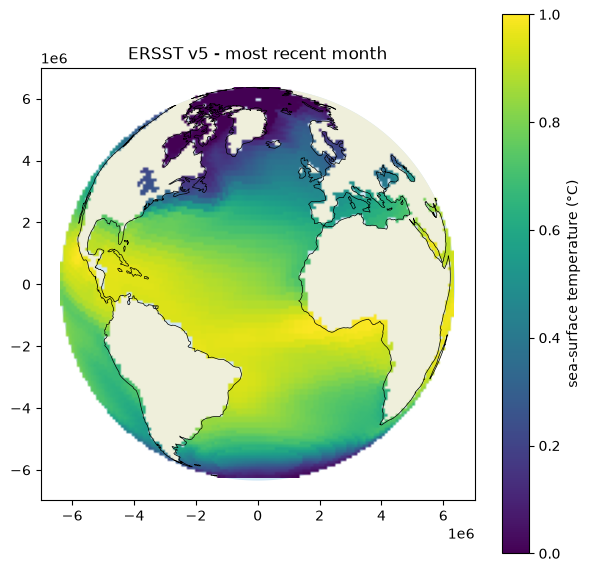

In [2]:
m = Map(crs=proj.orthographic(lon=-30, lat=20), globe=True, figsize=(7, 7))
backdrop(m, ocean=True)
m.field(sst, style='sea_surface_temperature')
annotate(m)
m.colorbar(label='sea-surface temperature (\u00b0C)')
m.set_title('ERSST v5 - most recent month')
m.fig;

## Spin the globe

The same field and basemap from three viewpoints - just move the orthographic centre. Centring the view on a pole (`orthographic(0, 90)`) gives a clean polar hemisphere.

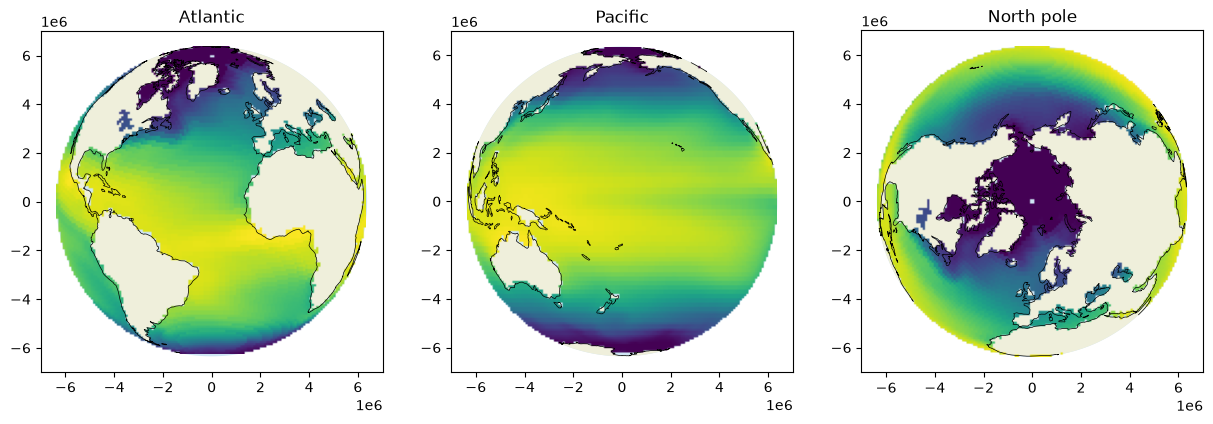

In [3]:
views = [('Atlantic', proj.orthographic(-30, 20)),
         ('Pacific', proj.orthographic(180, 0)),
         ('North pole', proj.orthographic(0, 90))]
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (name, crs) in zip(axes, views):
    m = Map(crs=crs, globe=True, ax=ax, fig=fig)
    backdrop(m, ocean=True); m.field(sst, style='sea_surface_temperature'); annotate(m)
    ax.set_title(name)
fig;

## Whole-world projections

For a flat world map, swap the CRS. **Mollweide** is equal-area, **Robinson** is a compromise projection, and **Web Mercator** is the web-tile standard (note how it stretches the high latitudes). Each gets a land + coastline basemap - the SST itself is the ocean, so no ocean fill is needed.

/home/runner/work/Digital-Earth/Digital-Earth/src/digitalearth/static/builders/projection.py:732: UserWarning: graticule() could not place 1 degree label(s): 180°. The display CRS 3857 gives their anchor no position inside the view the figure is framed on; frame the map on a region that holds them, or pass labels=False.
  warnings.warn(


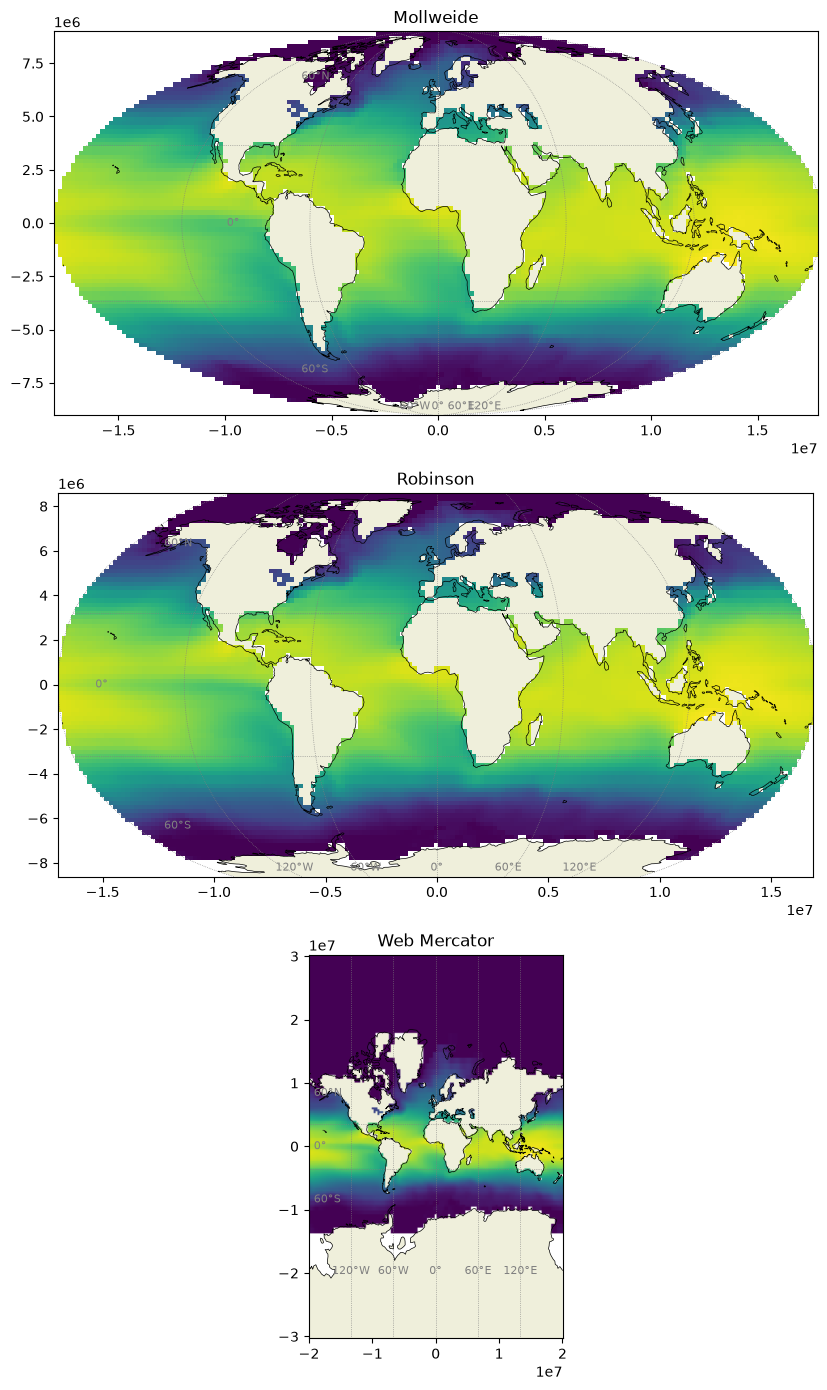

In [4]:
worlds = [('Mollweide', proj.mollweide()), ('Robinson', proj.robinson()), ('Web Mercator', proj.web_mercator())]
fig, axes = plt.subplots(3, 1, figsize=(9, 14))
for ax, (name, crs) in zip(axes, worlds):
    m = Map(crs=crs, ax=ax, fig=fig)
    backdrop(m); m.field(sst, style='sea_surface_temperature'); annotate(m, step=60)
    ax.set_title(name)
fig.tight_layout(); fig;

## Temperature anomaly

The real power of a climate record is the **anomaly**. Subtract the 52-year mean from the most recent month and draw the difference on the globe with the diverging `anomaly` preset - warm where the ocean ran above average, cool where it ran below.

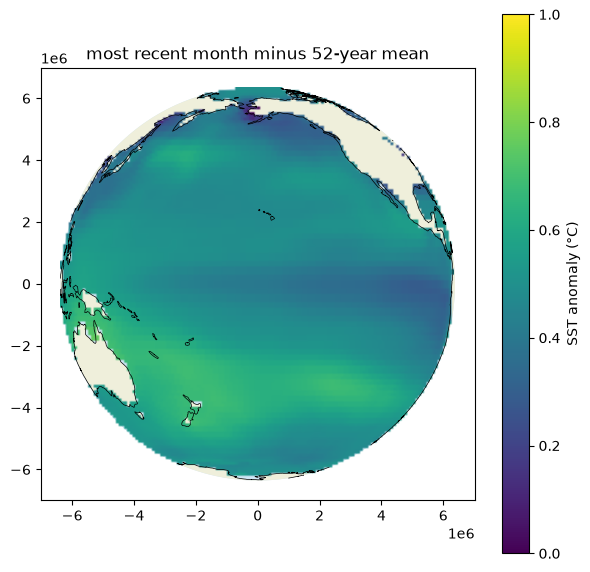

In [5]:
cube = nc.read_array().astype('float32'); cube = np.where(cube < -1e30, np.nan, cube)
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)   # all-NaN land columns
    climatology = np.nanmean(cube, axis=0)
anomaly = to_dataset(cube[-1] - climatology)
m = Map(crs=proj.orthographic(-160, 0), globe=True, figsize=(7, 7))
backdrop(m, ocean=True)
m.field(anomaly, style='anomaly')
annotate(m)
m.colorbar(label='SST anomaly (\u00b0C)')
m.set_title('most recent month minus 52-year mean')
m.fig;

## The seasonal swing

Averaging the record six months apart and differencing exposes the hemispheric seasonal cycle - one hemisphere warms as the other cools. The diverging scale is driven directly with `color_scale='midpoint'`.

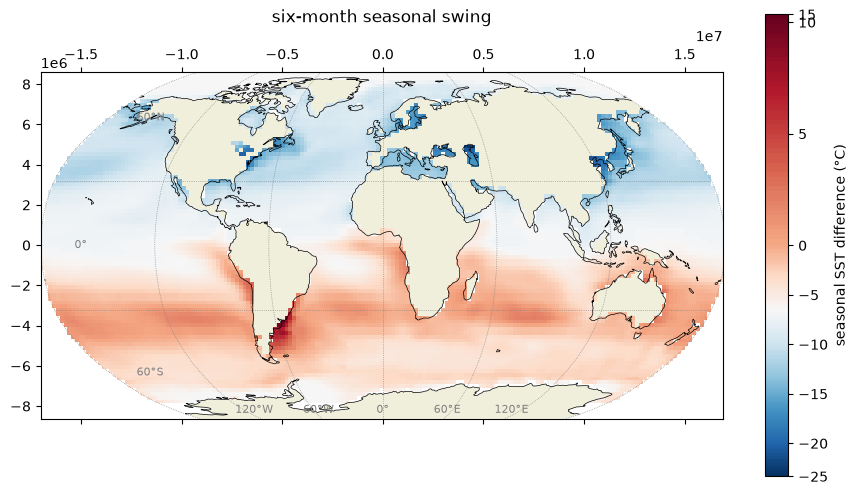

In [6]:
with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)
    swing = np.nanmean(cube[0::12], axis=0) - np.nanmean(cube[6::12], axis=0)
m = Map(crs=proj.robinson(), figsize=(11, 6))
backdrop(m)
m.field(to_dataset(swing), color_scale='midpoint', midpoint=0, cmap='RdBu_r')
annotate(m, step=60)
m.colorbar(label='seasonal SST difference (\u00b0C)')
m.set_title('six-month seasonal swing')
m.fig;